<a href="https://colab.research.google.com/github/ushkgowda/Multi-Domain-Data-Analysis-Portfolio-5-Real--Projects/blob/main/project2_student_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 2: Student Performance Analysis
**Portfolio: Multi-Domain Data Analysis** | Domain: Education

**Goals:** calculate pass/fail rates, analyze subject performance, measure the impact of attendance on scores, and recommend actions.

> **Simulated data.** No real student dataset was supplied, so `student_performance.csv` comes from a seeded generator (`generate_data.py`). The effects of attendance, study hours, tutoring and parental education were built into it, so this notebook demonstrates the method, not real-world findings. Swap in a real CSV with the same columns to get real results.

**Pass rule:** 40 or more in a subject; overall pass requires all five subjects.

## 1. Setup and loading

In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

PASS = 40
SUBJ = ["Math", "Science", "English", "History", "Computer_Science"]
raw = pd.read_csv("/content/student_performance.csv")
print("Shape:", raw.shape)
raw.head()

Shape: (1209, 14)


,Student_ID,Gender,Grade,Section,Parental_Education,Internet_Access,Extra_Tutoring,Study_Hours_Week,Attendance_Pct,Math,Science,English,History,Computer_Science
0,S1849,Male,12,B,High school or less,No,No,4.0,69.9,49.0,31.0,42.0,35.0,50.0
1,S1514,Female,10,B,Postgraduate,Yes,Yes,5.7,65.6,16.0,44.0,28.0,34.0,21.0
2,S1758,Female,9,C,Postgraduate,Yes,Yes,10.7,65.5,35.0,50.0,57.0,43.0,64.0
3,S1522,Female,9,A,High school or less,Yes,No,10.5,97.4,76.0,59.0,70.0,69.0,63.0
4,S1931,Female,10,D,Some college,Yes,No,5.3,87.7,67.0,66.0,78.0,63.0,73.0


## 2. Data cleaning and validation

In [3]:
print("Missing values:"); print(raw.isnull().sum()[raw.isnull().sum() > 0].to_string())
print("\nDuplicate rows:", raw.duplicated().sum())
print("Scores outside 0-100:", int(sum(((raw[s] < 0) | (raw[s] > 100)).sum() for s in SUBJ)))
print("Attendance above 100:", int((raw.Attendance_Pct > 100).sum()))

Missing values:
Study_Hours_Week    12
Math                14
Science             12
English             12
History             19
Computer_Science    21

Duplicate rows: 9
Scores outside 0-100: 6
Attendance above 100: 5


In [4]:
df = raw.drop_duplicates().copy()
for s in SUBJ:                                   # invalid scores -> missing (not guessed)
    df.loc[(df[s] < 0) | (df[s] > 100), s] = np.nan
df.loc[df.Attendance_Pct > 100, "Attendance_Pct"] = 100   # cap impossible attendance

df["Avg_Score"] = df[SUBJ].mean(axis=1)
complete = df[SUBJ].notna().all(axis=1)
df["Overall_Result"] = np.where(complete, np.where((df[SUBJ] >= PASS).all(axis=1), "Pass", "Fail"), "Incomplete")
df["Grade_Band"] = pd.cut(df.Avg_Score, [-1, 39.99, 49.99, 64.99, 79.99, 100], labels=["F (<40)", "D (40-49)", "C (50-64)", "B (65-79)", "A (80+)"])
df["Attendance_Band"] = pd.cut(df.Attendance_Pct, [0, 75, 85, 95, 100], labels=["<75%", "75-85%", "85-95%", "95-100%"])
df["Study_Band"] = pd.cut(df.Study_Hours_Week, [0, 4, 8, 12, 100], labels=["0-4h", "4-8h", "8-12h", "12h+"])
c = df[df.Overall_Result != "Incomplete"]
print("Rows after cleaning:", len(df), "| students with all 5 scores:", len(c))

Rows after cleaning: 1200 | students with all 5 scores: 1117


Missing values are **not imputed**. Subject statistics use available scores; the overall pass rate uses only students with all five scores.

## 3. Pass/fail analysis

Overall pass rate: 71.5%


,students,share
0,799,71.5
1,146,13.1
2,67,6.0
3,56,5.0
4,28,2.5
5,21,1.9


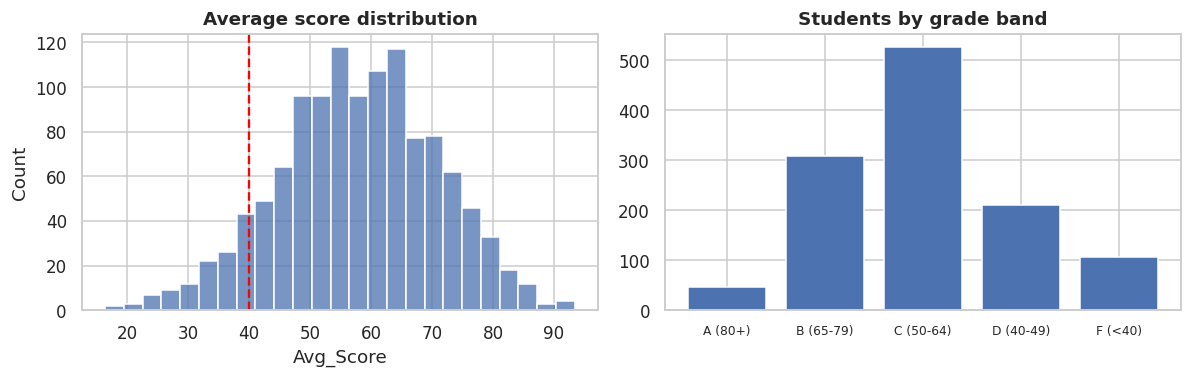

In [5]:
print("Overall pass rate: %.1f%%" % ((c.Overall_Result == "Pass").mean() * 100))
n_failed = (c[SUBJ] < PASS).sum(axis=1).value_counts().sort_index()
display(n_failed.rename("students").to_frame().assign(share=lambda d: (d.students / len(c) * 100).round(1)))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(df.Avg_Score.dropna(), bins=25, ax=axs[0]); axs[0].axvline(PASS, color="red", ls="--"); axs[0].set_title("Average score distribution")
gd = df.Grade_Band.value_counts().reindex(["A (80+)", "B (65-79)", "C (50-64)", "D (40-49)", "F (<40)"])
axs[1].bar(gd.index, gd.values); axs[1].set_title("Students by grade band"); axs[1].tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

## 4. Subject performance

,n,mean,median,std,pass_rate,pct_80_plus
subject,,,,,,
Math,1180,54.1,54.0,14.9,82.5,4.2
Science,1188,56.8,57.0,15.4,87.5,7.7
English,1188,59.4,60.0,15.2,90.0,9.5
History,1181,58.5,59.0,15.7,89.2,9.3
Computer_Science,1179,60.6,61.0,15.5,91.3,11.9


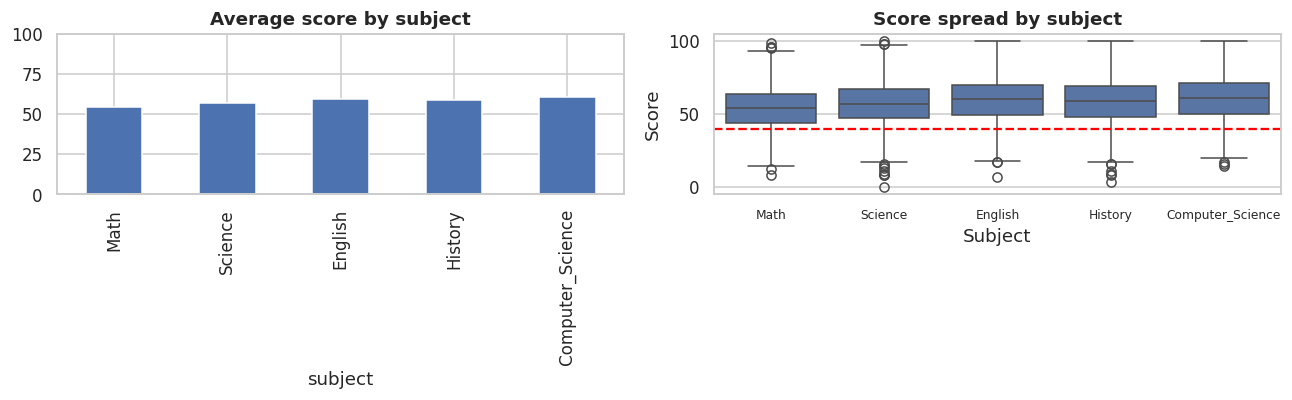

In [6]:
rows = []
for s in SUBJ:
    x = df[s].dropna()
    rows.append(dict(subject=s, n=len(x), mean=x.mean(), median=x.median(), std=x.std(), pass_rate=(x >= PASS).mean() * 100, pct_80_plus=(x >= 80).mean() * 100))
subj = pd.DataFrame(rows).set_index("subject").round(1); display(subj)

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
subj["mean"].plot.bar(ax=axs[0], color="C0"); axs[0].set_title("Average score by subject"); axs[0].set_ylim(0, 100)
sns.boxplot(data=df[SUBJ].melt(var_name="Subject", value_name="Score").dropna(), x="Subject", y="Score", ax=axs[1]); axs[1].axhline(PASS, color="red", ls="--")
axs[1].set_title("Score spread by subject"); axs[1].tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

## 5. Attendance impact

Pearson r = 0.57 (p = 1.5e-104) | Spearman rho = 0.54
Slope: +0.57 points per 1% attendance | R-squared = 0.33
Correlation with attendance by subject: {'Math': np.float64(0.49), 'Science': np.float64(0.49), 'English': np.float64(0.5), 'History': np.float64(0.47), 'Computer_Science': np.float64(0.48)}


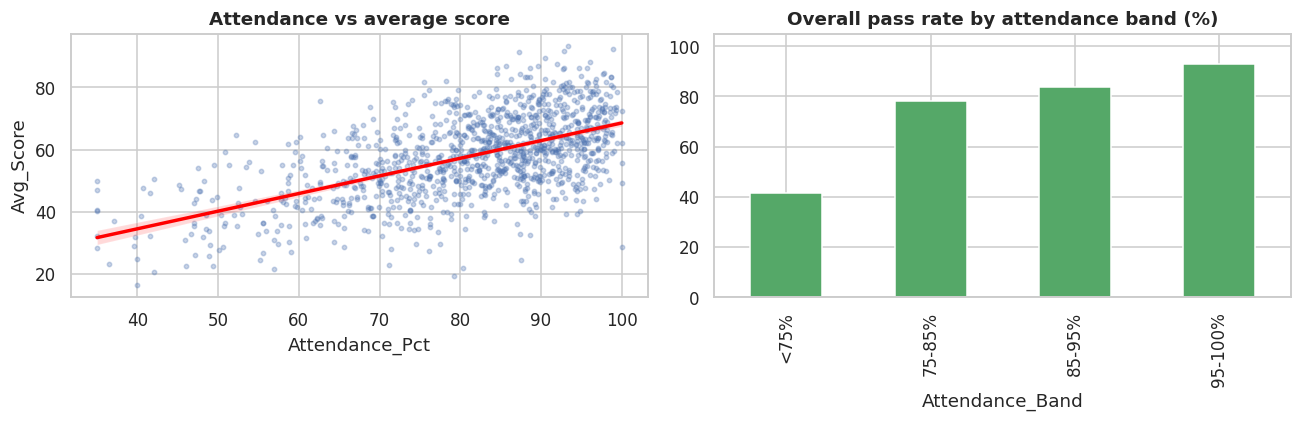

,students,avg_score,pass_rate
Attendance_Band,,,
<75%,311,47.6,41.5
75-85%,301,58.3,78.1
85-95%,367,62.8,83.7
95-100%,138,66.8,92.8


Chi-square (pass/fail vs band): p = 2.3e-43


In [7]:
d = df.dropna(subset=["Attendance_Pct", "Avg_Score"])
pr = stats.pearsonr(d.Attendance_Pct, d.Avg_Score); sp = stats.spearmanr(d.Attendance_Pct, d.Avg_Score)
lr = stats.linregress(d.Attendance_Pct, d.Avg_Score)
print("Pearson r = %.2f (p = %.1e) | Spearman rho = %.2f" % (pr[0], pr[1], sp[0]))
print("Slope: +%.2f points per 1%% attendance | R-squared = %.2f" % (lr.slope, lr.rvalue ** 2))
print("Correlation with attendance by subject:", {s: round(df[[s, "Attendance_Pct"]].dropna().corr().iloc[0, 1], 2) for s in SUBJ})

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
sns.regplot(data=d, x="Attendance_Pct", y="Avg_Score", scatter_kws={"s": 8, "alpha": .3}, line_kws={"color": "red"}, ax=axs[0]); axs[0].set_title("Attendance vs average score")
band = c.groupby("Attendance_Band", observed=True).agg(students=("Avg_Score", "size"), avg_score=("Avg_Score", "mean"), pass_rate=("Overall_Result", lambda s: (s == "Pass").mean() * 100)).round(1)
band.pass_rate.plot.bar(ax=axs[1], color="C2"); axs[1].set_title("Overall pass rate by attendance band (%)"); axs[1].set_ylim(0, 105)
plt.tight_layout(); plt.show(); display(band)
print("Chi-square (pass/fail vs band): p = %.1e" % stats.chi2_contingency(pd.crosstab(c.Attendance_Band, c.Overall_Result))[1])

## 6. Other factors

Study hours vs score: r = 0.22
Tutoring: 60.4 vs 56.8, p = 6.2e-05
Parental_Education: p = 0.000
Gender: p = 0.651
Grade: p = 0.680
Section: p = 0.423
Internet access: +1.8 points, p = 0.083


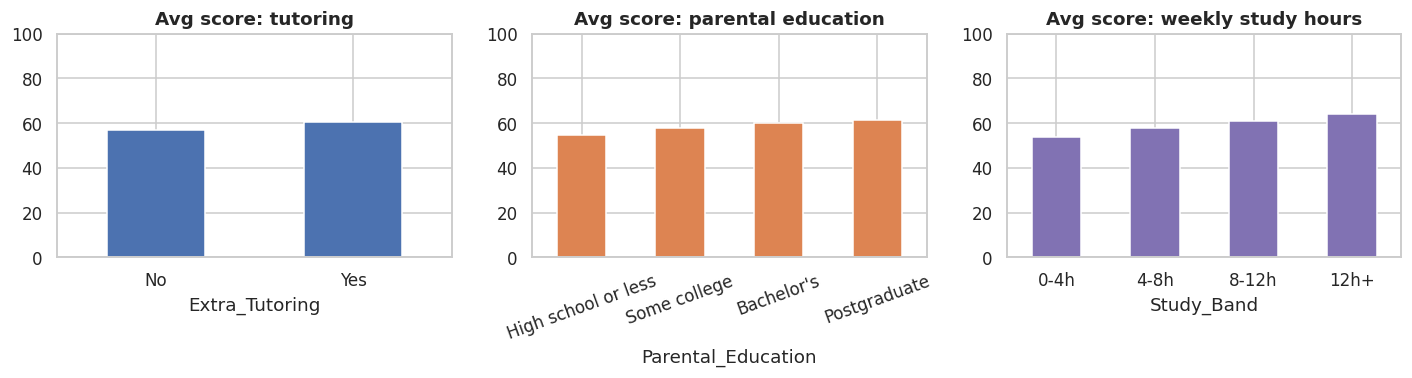

In [8]:
ds = df.dropna(subset=["Study_Hours_Week", "Avg_Score"])
print("Study hours vs score: r = %.2f" % stats.pearsonr(ds.Study_Hours_Week, ds.Avg_Score)[0])
y, n = c[c.Extra_Tutoring == "Yes"].Avg_Score, c[c.Extra_Tutoring == "No"].Avg_Score
print("Tutoring: %.1f vs %.1f, p = %.1e" % (y.mean(), n.mean(), stats.ttest_ind(y, n, equal_var=False).pvalue))
for col in ["Parental_Education", "Gender", "Grade", "Section"]:
    p = stats.f_oneway(*[g.Avg_Score for _, g in c.groupby(col)]).pvalue if c[col].nunique() > 2 else stats.ttest_ind(*[g.Avg_Score for _, g in c.groupby(col)], equal_var=False).pvalue
    print(f"{col}: p = {p:.3f}")
yi, ni = c[c.Internet_Access == "Yes"].Avg_Score, c[c.Internet_Access == "No"].Avg_Score
print("Internet access: %+.1f points, p = %.3f" % (yi.mean() - ni.mean(), stats.ttest_ind(yi, ni, equal_var=False).pvalue))

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
c.groupby("Extra_Tutoring").Avg_Score.mean().plot.bar(ax=axs[0], rot=0); axs[0].set_title("Avg score: tutoring")
c.groupby("Parental_Education").Avg_Score.mean().reindex(["High school or less", "Some college", "Bachelor's", "Postgraduate"]).plot.bar(ax=axs[1], rot=20, color="C1"); axs[1].set_title("Avg score: parental education")
c.groupby("Study_Band", observed=True).Avg_Score.mean().plot.bar(ax=axs[2], rot=0, color="C4"); axs[2].set_title("Avg score: weekly study hours")
for a in axs: a.set_ylim(0, 100)
plt.tight_layout(); plt.show()

Per 1% attendance: +0.57 | per weekly study hour: +0.95 | tutoring: +3.9 | R-squared = 0.39


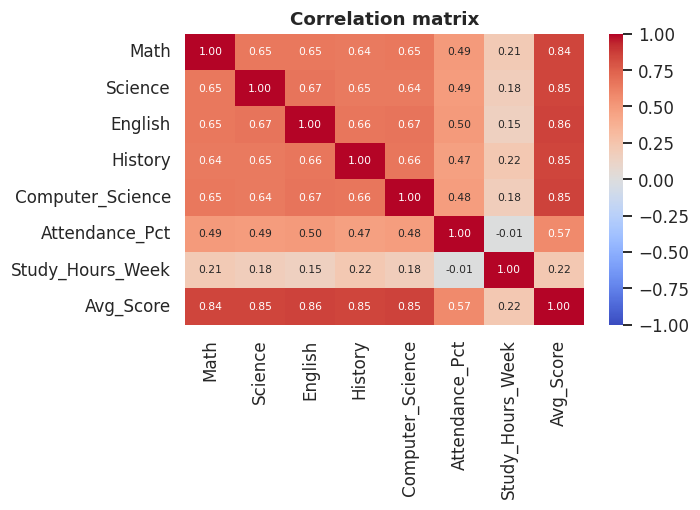

In [9]:
# Combined model: attendance + study hours + tutoring
X = df.dropna(subset=["Avg_Score", "Attendance_Pct", "Study_Hours_Week"])
A = np.column_stack([np.ones(len(X)), X.Attendance_Pct, X.Study_Hours_Week, (X.Extra_Tutoring == "Yes").astype(int)])
beta = np.linalg.lstsq(A, X.Avg_Score.values, rcond=None)[0]
r2 = 1 - (X.Avg_Score.values - A @ beta).var() / X.Avg_Score.var()
print("Per 1%% attendance: %+.2f | per weekly study hour: %+.2f | tutoring: %+.1f | R-squared = %.2f" % (beta[1], beta[2], beta[3], r2))

plt.figure(figsize=(6.5, 4.8)); sns.heatmap(df[SUBJ + ["Attendance_Pct", "Study_Hours_Week", "Avg_Score"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Correlation matrix"); plt.tight_layout(); plt.show()

## 7. At-risk students

In [10]:
low_att = df.Attendance_Pct < 75; low_score = df.Avg_Score < 50
print("Low attendance (<75%%): %d | both flags: %d | either flag: %d (%.0f%%)" % (low_att.sum(), (low_att & low_score).sum(), (low_att | low_score).sum(), (low_att | low_score).mean() * 100))
print("Fail rate, attendance <75%%: %.1f%%" % ((c[c.Attendance_Pct < 75].Overall_Result == "Fail").mean() * 100))
print("Fail rate, attendance >=95%%: %.1f%%" % ((c[c.Attendance_Pct >= 95].Overall_Result == "Fail").mean() * 100))

Low attendance (<75%): 326 | both flags: 194 | either flag: 449 (37%)
Fail rate, attendance <75%: 58.6%
Fail rate, attendance >=95%: 7.0%


## 8. Findings and recommendations

| Finding | Evidence |
|---|---|
| Attendance is the strongest factor | r = 0.57; +0.57 points per 1% attendance; fail rate 58.6% (<75%) vs 7.0% (95%+) |
| Math is the weakest subject | mean 54.1, pass rate 82.5% |
| Tutoring and study hours associated with gains | about +3.9 points tutoring, +0.95 per weekly hour (combined model) |
| Parental education gradient | 54.8 (HS or less) vs 61.5 (postgraduate) |
| No gap by gender, grade or section | all p > 0.4 |

**Recommendations:** (1) attendance early-warning system at 75%; (2) mentors for the 194 students with low attendance and low scores; (3) remedial Math; (4) short revision programs for the 146 students who failed exactly one subject; (5) wider tutoring access for first-generation students; (6) study-skills coaching; (7) mandatory five-subject score entry; (8) track outcomes to test what works.

**Limitations:** simulated data; associations are not proof of cause; pass mark and grade bands are assumptions.